In [2]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

In [3]:
df = pd.read_csv("sales_data_sample.csv", encoding = "unicode_escape")
print(df.head())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...           CITY  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...            NYC   
1    5/7/2003 0:00  Shipped       2         5     2003  ...          Reims   
2    7/1/2003 0:00  Shipped       3         7     2003  ...          Paris   
3   8/25/2003 0:00  Shipped       3         8     2003  ...       Pasadena   
4  10/10/2003 0:00  Shipped       4        10     2003  ...  San Francisco   

   STATE POSTALCODE COUNTRY TERRITORY CONTACTLASTNAME CONTACTFIRSTNAME  \
0     NY      10022     

In [4]:
features = ["QUANTITYORDERED", "PRICEEACH", "SALES"]
X = df[features].copy()
X = X.fillna(X.median())
print(X)

      QUANTITYORDERED  PRICEEACH    SALES
0                  30      95.70  2871.00
1                  34      81.35  2765.90
2                  41      94.74  3884.34
3                  45      83.26  3746.70
4                  49     100.00  5205.27
...               ...        ...      ...
2818               20     100.00  2244.40
2819               29     100.00  3978.51
2820               43     100.00  5417.57
2821               34      62.24  2116.16
2822               47      65.52  3079.44

[2823 rows x 3 columns]


In [5]:
X.isnull().sum()

QUANTITYORDERED    0
PRICEEACH          0
SALES              0
dtype: int64

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [7]:
wcss = []

In [9]:
for i in range(1, 11):
    kMeans = KMeans(n_clusters = i, random_state = 42, n_init = 10)
    kMeans.fit(X_scaled)
    wcss.append(kMeans.inertia_)

In [10]:
wcss

[8469.0,
 5091.753335644901,
 3082.6505184877296,
 2367.995702596402,
 1927.8951485815423,
 1658.2138871031061,
 1447.9322063854336,
 1281.4909346420086,
 1172.5237680970872,
 1073.185548444642]

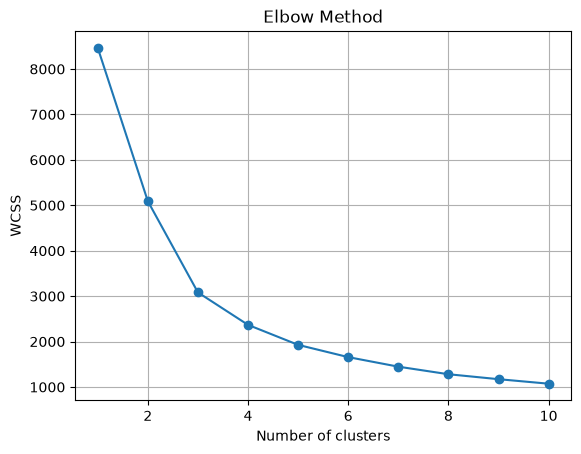

In [16]:
import matplotlib.pyplot as plt  
plt.plot(range(1, 11), wcss, marker = 'o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [19]:
k = 3
kMeans = KMeans(n_clusters = k, random_state = 42, n_init = 10)
df['KMeans_Cluster'] = kMeans.fit_predict(X_scaled)

In [20]:
print("\nK Means Cluster Counts : ")
print(df['KMeans_Cluster'].value_counts().sort_index())


K Means Cluster Counts : 
KMeans_Cluster
0     881
1     907
2    1035
Name: count, dtype: int64


In [21]:
score = silhouette_score(X_scaled, df['KMeans_Cluster'])

In [22]:
print("\nSilhouette Score : ", round(score, 4))


Silhouette Score :  0.4121


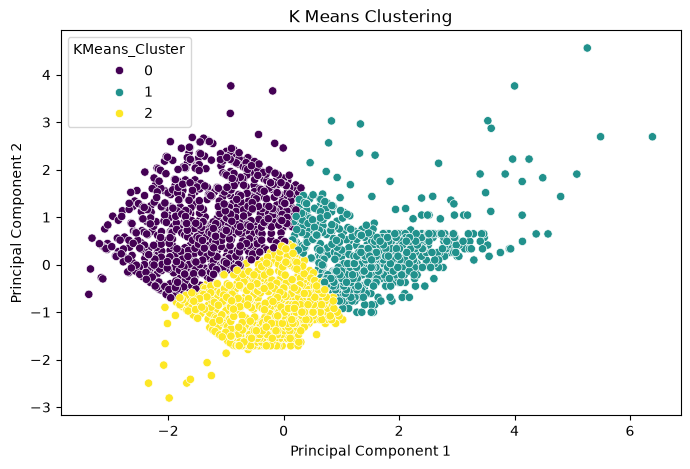

In [26]:
pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize = (8, 5))
import seaborn as sns
sns.scatterplot(x = X_pca[:, 0], y = X_pca[:, 1], hue = df['KMeans_Cluster'], palette = 'viridis')
plt.title('K Means Clustering')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

In [27]:
# Hierarchial Clustering
hierarchical = AgglomerativeClustering(n_clusters = k)
df['Hierarchical_Cluster'] = hierarchical.fit_predict(X_scaled)
print("\nHierarchical Cluster Counts : ")
print(df['Hierarchical_Cluster'].value_counts().sort_index())


Hierarchical Cluster Counts : 
Hierarchical_Cluster
0    1014
1     685
2    1124
Name: count, dtype: int64


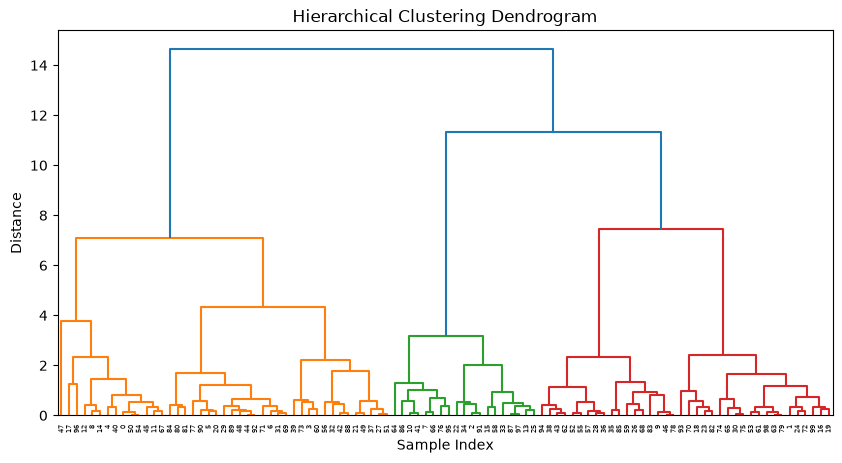

In [29]:
# Dendrogram
sample_size = min(100, len(X_scaled))
sample_indices = np.random.default_rng(42).choice(
    len(X_scaled), size = sample_size, replace = False
)
Z = linkage(X_scaled[sample_indices], method = 'ward')
plt.figure(figsize = (10, 5))
dendrogram(Z)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()

In [30]:
# Cluster Summary
print("\nK Means Clusters Summary")
print(df.groupby('KMeans_Cluster')[features].mean().round(2))

print("\nHierarchical Cluster Summary")
print(df.groupby('Hierarchical_Cluster')[features].mean().round(2))


K Means Clusters Summary
                QUANTITYORDERED  PRICEEACH    SALES
KMeans_Cluster                                     
0                         35.13      57.13  2009.83
1                         43.85      96.64  5584.01
2                         27.39      94.87  3089.15

Hierarchical Cluster Summary
                      QUANTITYORDERED  PRICEEACH    SALES
Hierarchical_Cluster                                     
0                               36.58      60.35  2238.07
1                               44.08      99.45  6081.75
2                               28.27      95.06  3200.38
